In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
import re
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
raw  = re.sub(r'-\d+$', '', name)                        # strip run-suffix -> raw dataset name
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| raw:', raw, '| category:', cat)

dataset: Filbin2018_Brain-2 | raw: Filbin2018_Brain | category: Brain


In [3]:
# resolve to the leaf matrix dir (as merge.py does) and load malignant cells
leaves = [dp for dp, sd, _ in os.walk(pth_in) if len(sd) == 0]
print('leaf dirs (no subdirs):', leaves)
assert len(leaves) == 1, 'expected a single SmartSeq2 leaf'
adata = load_CCCA_adata(leaves[0], verbose=False)
adata.var_names_make_unique()
print('loaded:', adata.shape, '| X max %.2f (log1p of TPM)' % adata.X.max())
print('cell_type:', adata.obs.cell_type.value_counts(dropna=False).to_dict())
adata = adata[adata.obs.cell_type == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

leaf dirs (no subdirs): ['../../../../../../data/unzip/CCCA/Data_Filbin2018_Brain']
loaded: (2587, 23686) | X max 12.80 (log1p of TPM)
cell_type: {'Malignant': 2259, 'Oligodendrocyte': 232, 'Macrophage': 96}
malignant: (2259, 23686) | samples: 6


In [4]:
# per-sample threshold: derived from the largest multiplicative gap in the sorted counts
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [667 489 438 283 241 141]
largest gap: 241 -> 141 (ratio 1.71)
derived threshold (geometric mean across gap) = 184
kept 5/6 samples -> 2118 cells


In [5]:
# gene filter + overdispersed feature selection + PCA (no sc.pp.scale, per reference protocol)
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
print('PCA variance ratio (head):', np.round(adata.uns['pca']['variance_ratio'][:12], 4))
print('n_pcs=20: variance ratio has flattened by PC~20 (SmartSeq2 depth); matches the 20/40 precedents.')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3583 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3583
PCA variance ratio (head): [0.051  0.0243 0.0168 0.0146 0.0131 0.0051 0.0045 0.0035 0.0033 0.0029
 0.0026 0.0024]
n_pcs=20: variance ratio has flattened by PC~20 (SmartSeq2 depth); matches the 20/40 precedents.


In [6]:
# integration sweep: per-neighborhood iLISI across theta x n_pcs (never a single global scalar)
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()
s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'sample iLISI (ideal {nsamp}); pre-Harmony PCA20: %.2f | PCA40: %.2f'
      % (ilisi(adata.obsm['X_pca'][:,:20], s), ilisi(adata.obsm['X_pca'][:,:40], s)))
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    print('  theta=%2d: npcs20 %.2f | npcs30 %.2f | npcs40 %.2f'
          % (th, ilisi(adata.obsm['X_pca_harmony'][:,:20], s),
                 ilisi(adata.obsm['X_pca_harmony'][:,:30], s),
                 ilisi(adata.obsm['X_pca_harmony'][:,:40], s)))
theta = 10
print('selected theta =', theta, '(mixing plateaus ~3.5/5; robust across n_pcs 20/30/40)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)

sample iLISI (ideal 5); pre-Harmony PCA20: 1.18 | PCA40: 1.20
  theta= 2: npcs20 2.94 | npcs30 3.02 | npcs40 3.06
  theta= 5: npcs20 3.44 | npcs30 3.49 | npcs40 3.46
  theta=10: npcs20 3.56 | npcs30 3.59 | npcs40 3.55
selected theta = 10 (mixing plateaus ~3.5/5; robust across n_pcs 20/30/40)


In [7]:
# neighbors -> UMAP on the integrated representation
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
# island removal: connected components of a UMAP radius graph at 6x median NN distance
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
n_removed = int((lab != main).sum()); n_islands = int(ncomp - 1)
print(f'connected components (6x radius): {ncomp} | removed {n_removed} detached cells in {n_islands} islands')
adata = adata[lab == main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('retained one connected component:', adata.shape[0], 'cells')

connected components (6x radius): 1 | removed 0 detached cells in 0 islands
retained one connected component: 2118 cells


In [8]:
# subtype annotation: data-derived from Filbin's published DIPG lineage scores
# (OPC-like stem/progenitor, OC-like oligodendrocytic, AC-like astrocytic; Filbin et al. 2018),
# each cell assigned to its dominant lineage-score program -> confirmed against those markers.
for c in ['opc_like', 'oc_like', 'ac_like']:
    adata.obs[c] = pd.to_numeric(adata.obs[c], errors='coerce').fillna(0.0)
lin_cols = ['opc_like', 'oc_like', 'ac_like']
lin_map = {'opc_like':'OPC-like', 'oc_like':'OC-like', 'ac_like':'AC-like'}
argmax = adata.obs[lin_cols].values.argmax(1)
adata.obs['celltype'] = pd.Categorical([lin_map[lin_cols[i]] for i in argmax])
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lineage subtypes:', adata.obs['celltype'].value_counts().to_dict())
print('cycling fraction per subtype:',
      adata.obs.groupby('celltype', observed=True)['cycling'].mean().round(2).to_dict())

lineage subtypes: {'OPC-like': 1153, 'OC-like': 572, 'AC-like': 393}
cycling fraction per subtype: {'AC-like': 0.11, 'OC-like': 0.22, 'OPC-like': 0.18}


5 samples share one continuous manifold; sample iLISI=3.56 of 5.
island removal removed 0 cells in 0 detached islands -> one connected component retained.
GATE 1: samples intermixed (iLISI 3.56/5) on one continuous H3-K27M glioma manifold -> GO


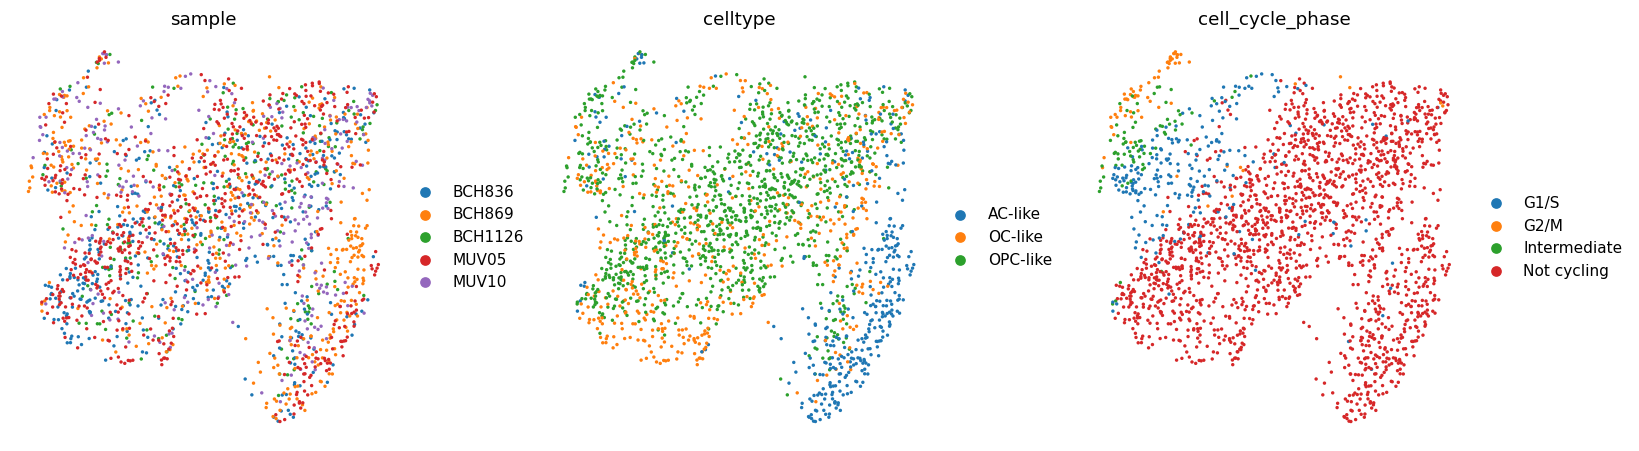

In [9]:
# GATE 1 visual evidence: mixing + continuity on the regenerated embedding
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col in zip(axes, ['sample', 'celltype', 'cell_cycle_phase']):
    sc.pl.umap(adata, color=col, size=20, frameon=False, show=False, ax=ax, title=col)
fig.tight_layout(); plt.show()
n_samp = adata.obs['sample'].nunique()
il = ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values)
print(f'{n_samp} samples share one continuous manifold; sample iLISI={il:.2f} of {n_samp}.')
print(f'island removal removed {n_removed} cells in {n_islands} detached islands -> one connected component retained.')
gate1 = 'GO' if (il > 1.5 and n_islands == 0) else 'NO-GO'
print(f'GATE 1: samples intermixed (iLISI {il:.2f}/{n_samp}) on one continuous H3-K27M glioma manifold -> {gate1}')

In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2118, 21106)


saved samples.pdf | cells: 2118


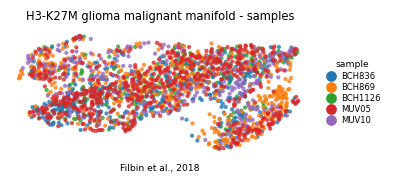

In [11]:
# samples.pdf: single sample-coloured manifold, house (3.5,1.5) horizontal strip
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('H3-K27M glioma malignant manifold - samples', size=7.5)
ax.text(.5, -.12, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])